# Poda Alfa-Beta en un árbol representado con listas de Python

Este cuaderno implementa un algoritmo de poda alfa-beta para un árbol de decisión representado como listas anidadas. La lista del árbol puede configurarse en la segunda celda de código.


- Un valor entero es una hoja.
- Una lista representa un nodo con hijos.
- El nodo raíz es un máximo.
- Los niveles alternan máximo y mínimo.

In [19]:
import random
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.patches import Patch

# Genera un árbol aleatorio como lista de listas con un máximo de 5 niveles y 50 nodos hoja.
def generate_random_list_tree(levels, leaf_nodes, min_value=-10, max_value=10, seed=None):
    if not 1 <= levels <= 5:
        raise ValueError('levels debe estar entre 1 y 5.')
    if not 1 <= leaf_nodes <= 50:
        raise ValueError('leaf_nodes debe estar entre 1 y 50.')

    rng = random.Random(seed)

    if levels == 1:
        return [rng.randint(min_value, max_value) for _ in range(leaf_nodes)]

    branch_count = min(5, max(2, leaf_nodes))
    base, remainder = divmod(leaf_nodes, branch_count)
    counts = [base + (1 if i < remainder else 0) for i in range(branch_count)]
    counts = [count for count in counts if count > 0]

    children = []
    for count in counts:
        if levels == 2:
            children.append([rng.randint(min_value, max_value) for _ in range(count)])
        else:
            next_seed = rng.randint(0, 10**9)
            children.append(generate_random_list_tree(levels - 1, count, min_value, max_value, next_seed))
    return children

# Configuración del árbol en la segunda celda.
# Ejemplo que sí activa poda alfa-beta.
tree = [[5, 2, -5], [-6, -4], [6, -3, 1]]

# También puedes usar una lista aleatoria como lista de listas:
# tree = generate_random_list_tree(levels=3, leaf_nodes=9, seed=7)


Valor minimax con poda alfa-beta: -3.0
Ruta óptima de decisión: (2, 1)
Ramas podadas:
  - Nodo: (1, 0) | motivo: corte por alfa


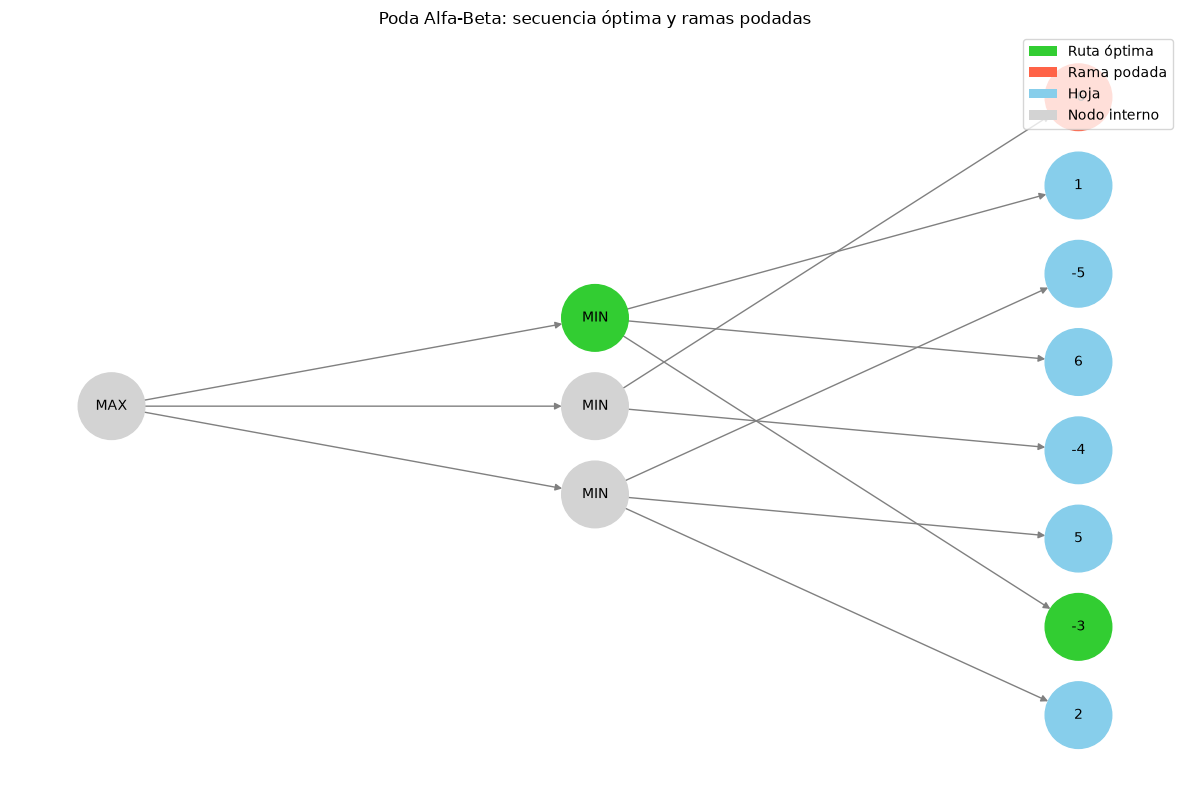

In [20]:
def is_leaf(node):
    return isinstance(node, (int, float))


def alpha_beta(node, depth=0, alpha=-float('inf'), beta=float('inf'), path=()):
    """Evalúa con Poda Alfa-Beta un árbol minimax representado con listas anidadas."""
    if is_leaf(node):
        return float(node), path, []

    if depth % 2 == 0:  # MAX
        best_value = -float('inf')
        best_path = ()
        pruned = []

        for idx, child in enumerate(node):
            child_value, child_path, child_pruned = alpha_beta(child, depth + 1, alpha, beta, path + (idx,))
            pruned.extend(child_pruned)
            if child_value > best_value:
                best_value = child_value
                best_path = child_path

            alpha = max(alpha, best_value)
            if beta <= alpha:
                pruned.append({'node': path + (idx,), 'reason': 'corte por beta'})
                break

        return best_value, best_path, pruned

    # MIN
    best_value = float('inf')
    best_path = ()
    pruned = []

    for idx, child in enumerate(node):
        child_value, child_path, child_pruned = alpha_beta(child, depth + 1, alpha, beta, path + (idx,))
        pruned.extend(child_pruned)
        if child_value < best_value:
            best_value = child_value
            best_path = child_path

        beta = min(beta, best_value)
        if beta <= alpha:
            pruned.append({'node': path + (idx,), 'reason': 'corte por alfa'})
            break

    return best_value, best_path, pruned


def build_tree_graph(tree, optimal_path=(), pruned_paths=()):
    G = nx.DiGraph()
    optimal_prefixes = {optimal_path[:i] for i in range(1, len(optimal_path) + 1)}
    pruned_set = set(pruned_paths)

    def add_node(node, path=()):
        node_id = path if path else ('root',)
        if is_leaf(node):
            G.add_node(node_id, depth=len(path), kind='leaf', label=str(node), display_label=str(node))
            return

        G.add_node(node_id, depth=len(path), kind='internal', label='MAX' if len(path) % 2 == 0 else 'MIN', display_label='MAX' if len(path) % 2 == 0 else 'MIN')
        for idx, child in enumerate(node):
            child_id = path + (idx,)
            G.add_edge(node_id, child_id)
            add_node(child, child_id)

    add_node(tree)

    colors = []
    for node in G.nodes():
        if node in pruned_set:
            colors.append('tomato')
        elif node in optimal_prefixes:
            colors.append('limegreen')
        elif G.nodes[node]['kind'] == 'leaf':
            colors.append('skyblue')
        else:
            colors.append('lightgray')

    pos = nx.multipartite_layout(G, subset_key='depth', align='vertical')
    return G, pos, colors


def mostrar_resultado(tree):
    valor, ruta_optima, ramas_podadas = alpha_beta(tree)
    pruned_paths = [item['node'] for item in ramas_podadas]
    G, pos, colors = build_tree_graph(tree, ruta_optima, pruned_paths)

    print(f'Valor minimax con poda alfa-beta: {valor}')
    print(f'Ruta óptima de decisión: {ruta_optima}')
    print('Ramas podadas:')
    if not ramas_podadas:
        print('  Ninguna')
    else:
        for item in ramas_podadas:
            print(f"  - Nodo: {item['node']} | motivo: {item['reason']}")

    fig, ax = plt.subplots(figsize=(12, 8))
    labels = {node: G.nodes[node]['display_label'] for node in G.nodes()}
    nx.draw(
        G,
        pos,
        with_labels=True,
        labels=labels,
        node_color=colors,
        node_size=2300,
        edge_color='gray',
        font_size=10,
        ax=ax,
    )

    legend_handles = [
        Patch(facecolor='limegreen', label='Ruta óptima'),
        Patch(facecolor='tomato', label='Rama podada'),
        Patch(facecolor='skyblue', label='Hoja'),
        Patch(facecolor='lightgray', label='Nodo interno'),
    ]
    ax.legend(handles=legend_handles, loc='upper right')
    ax.set_title('Poda Alfa-Beta: secuencia óptima y ramas podadas')
    plt.tight_layout()
    plt.show()

    return valor, ruta_optima, ramas_podadas


valor, ruta, podadas = mostrar_resultado(tree)

